In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import scipy.constants as cte
import matplotlib.animation as animation
from IPython.display import Image, display

# Temas Selectos de Física Atómica I
## Actividad 2. Expansión de un sistema de N cuerpos sometidos a caída libre
 Ángel André Aguilar Contreras

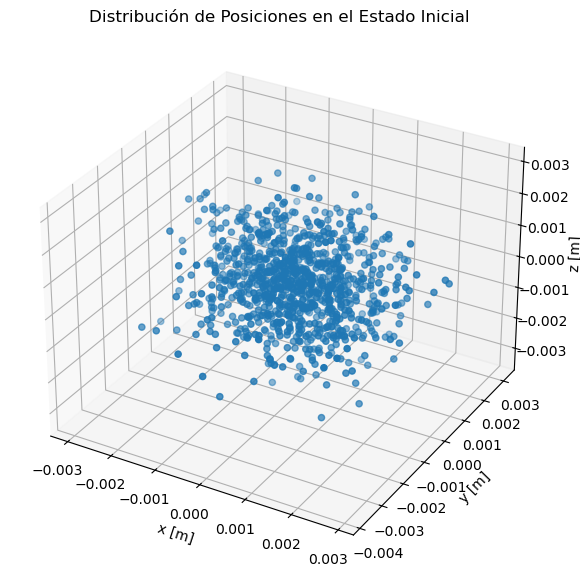

In [2]:
"""
1. Definir parámetros iniciales de la simulación
Crear una distribución espacial y de velocidades para 1000 átomos de rubidio
85. La distribución espacial debe ser esférica y gaussiana, con centro en el
origen y dispersión de 1mm. La distribución de velocidades debe ser gaussiana,
centrada en el origen y con una dispersión de 0.5m/s. Grafique las partículas en
el espacio 3D.
"""
particulas = 1000 # Cantidad de Partículas
m = 1.40999e-25 # Masa atómica del Rb85 [kg]

r_sigma = 0.001 # dispersión de posiciones [m]
v_sigma = 0.5 # dispersión de velocidades [m/s]

r_mu = np.array([0,0,0]) # media de posiciones iniciales [m]
v_mu = np.array([0,0,0]) # media de velocidades iniciales [m/s]

r0 = np.random.normal(loc=0.0, scale=r_sigma, size=(particulas, 3)) + r_mu # Distribución normal de posiciones
v0 = np.random.normal(loc=0.0, scale=v_sigma, size=(particulas, 3)) + v_mu # Distribución normal de velocidades

"""
Presentación de posiciones iniciales
"""
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(projection='3d')
ax.scatter(r0[:,0], r0[:,1], r0[:,2])
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_zlabel("z [m]")
plt.title(f"Distribución de Posiciones en el Estado Inicial")
plt.show()

In [3]:
"""
Definición de funciones para ajuste gaussiano  y animación de evolución temporal.
"""
def fit_gauss(all_data, bins = 30, **kargs):
    """
    Realiza y grafica un ajuste gaussiano independiente para las tres dimensiones (x, y, z).

    Parámetros:
    -----------
    all_data : numpy.ndarray
        Matriz de forma (N, 3) con las posiciones de N partículas en los ejes X, Y y Z.
    bins : int, opcional
        Número de contenedores para el histograma. Por defecto es 30.
    **kargs : dict
        - label (str): Etiqueta o unidades para el eje horizontal (ej. 'Posición [m]').
        - title (str): Texto complementario para el título superior del gráfico.

    Devuelve:
    --------
    mu : list
        Medias ajustadas para cada eje [mu_x, mu_y, mu_z].
    sigma : list
        Desviaciones estándar ajustadas para cada eje [sigma_x, sigma_y, sigma_z].
    """
    fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey = True, sharex= False)
    
    axes, colors = ["x", "y", "z"], ["darkmagenta", "forestgreen", "navy"]
    label = kargs.get('label', '')
    title = kargs.get('title', '')
    mu, sigma = [],[]  
    for i, axe in enumerate(axes):
        data = all_data[:, i]
        mu_fit, sigma_fit = norm.fit(data) # Ajusste gaussiano sobre la i-ésima coordenada de los datos
        mu.append(mu_fit)
        sigma.append(sigma_fit)
        weights = np.ones(len(data))/len(data) # Ajsute de los pesos para la distribución adecuada de bins
        count, bin_edges, _ = ax[i].hist(data, bins=bins, alpha=0.6, color=colors[i], edgecolor='black', label='Datos', weights = weights) # histograma
    
        x = np.linspace(mu_fit - 4*sigma_fit, mu_fit + 4*sigma_fit, 200)
        pdf_fit = norm.pdf(x, mu_fit, sigma_fit)*(bin_edges[1]-bin_edges[0])
        ax[i].plot(x, pdf_fit, 'r-', linewidth=1, label=f'Ajuste Normal\n$\mu$={mu_fit:.3f}, $\sigma$={sigma_fit:.3f}') # ajuste gaussiano
        
        ax[i].set_xlim(mu_fit - 4*sigma_fit, mu_fit + 4*sigma_fit)
        ax[i].set_title(f'Eje {axe}')
        ax[i].set_xlabel(f'{label}')
        if i == 0: ax[i].set_ylabel('Densidad de Probabilidad') 
        ax[i].legend(fontsize=9)
        ax[i].grid(True, alpha=0.3)
    
    
    plt.suptitle(f"Ajute Normal para cada eje {title}")
    plt.tight_layout()
    return mu, sigma

def compare_fit(mu_0, mu_1, sigma_0, sigma_1, **kargs):
    fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey = True, sharex= False)
    
    axes, colors = ["x", "y", "z"], ["darkmagenta", "forestgreen", "navy"]
    label = kargs.get('label', '')
    title = kargs.get('title', '')

    for i, axe in enumerate(axes):
        sigma = max(sigma_0, sigma_1[i])
        x_min = min(mu_0[i] - 4*sigma, mu_1[i] - 4*sigma)
        x_max = max(mu_0[i] + 4*sigma, mu_1[i] + 4*sigma)
        x = np.linspace(x_min, x_max, 1000)

        pdf_0 = norm.pdf(x, mu_0[i], sigma_0)
        pdf_1 = norm.pdf(x, mu_1[i], sigma_1[i])

        ax[i].plot(x, pdf_0, 'r-', linewidth=1, label=f'Ajuste Incial \n$\mu$={mu_0[i]:.3f}, $\sigma$={sigma_0:.3f}') # ajuste gaussiano
        ax[i].plot(x, pdf_1, 'b-', linewidth=1, label=f'Ajuste Final \n$\mu$={mu_1[i]:.3f}, $\sigma$={sigma_1[i]:.3f}') # ajuste gaussiano

        ax[i].set_title(f'Eje {axe}')
        ax[i].set_xlabel(f'{label}')
        if i == 0: ax[i].set_ylabel('Densidad de Probabilidad') 
        ax[i].legend(fontsize=9)
        ax[i].grid(True, alpha=0.3)
    
    
    plt.suptitle(f"Comparación de ajustes normales {title}")
    plt.tight_layout()

def animate(r0, v0, a, t, **kargs):
    """
    Simula y genera un GIF de la evolución temporal de partículas con aceleración constante.

    Parámetros:
    -----------
    r0 : numpy.ndarray
        Matriz de posiciones iniciales de forma (N, 3).
    v0 : numpy.ndarray
        Matriz de velocidades iniciales de forma (N, 3) o vector (3,).
    a : numpy.ndarray o float
        Vector de aceleración de las partículas.
    t : float
        Tiempo total de la simulación en segundos.
    **kargs : dict
        - dt (float): Paso de tiempo de simulación. Por defecto 0.05 s.
        - lim (float): Límite simétrico de los ejes 3D [-lim, lim]. Por defecto 0.5.
        - filename (str): Nombre del archivo GIF a guardar. Por defecto 'simulation.gif'.
    """
    dt = kargs.get('dt', 0.05)
    steps = int(t/dt)

    fig = plt.figure(figsize=(5, 5))
    ax = fig.add_subplot(projection='3d')

    lim = kargs.get('lim', 0.5)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_zlim(-lim, lim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')

    scatter = ax.scatter(r0[:, 0], r0[:, 1], r0[:, 2])

    def refresh(frame): # función auxiliar para refrescar loss frames de la animación
        t = frame * dt
        v = v0 + a*t
        r = r0 + v0*t + 0.5*a*t**2    
        scatter._offsets3d = (r[:, 0], r[:, 1], r[:, 2])
        ax.set_title(f"Evolución temporal a t = {t:.4f} s")
        return scatter,
    
    ani = animation.FuncAnimation(fig, refresh, frames=steps, interval=40) # Generar animación
    plt.close(fig)  # Oculta la figura estática doble
    filename = kargs.get('filename', 'simulacion.gif')
    ani.save(filename, writer='pillow', fps=25, dpi= 80) # Usar pillow para transformar las matrices en  GIF
    display(Image(filename=filename)) # Guardar la simulación para reducir el coste de RAM

Temperatura inicial del sistema: 5.1591E-06 K


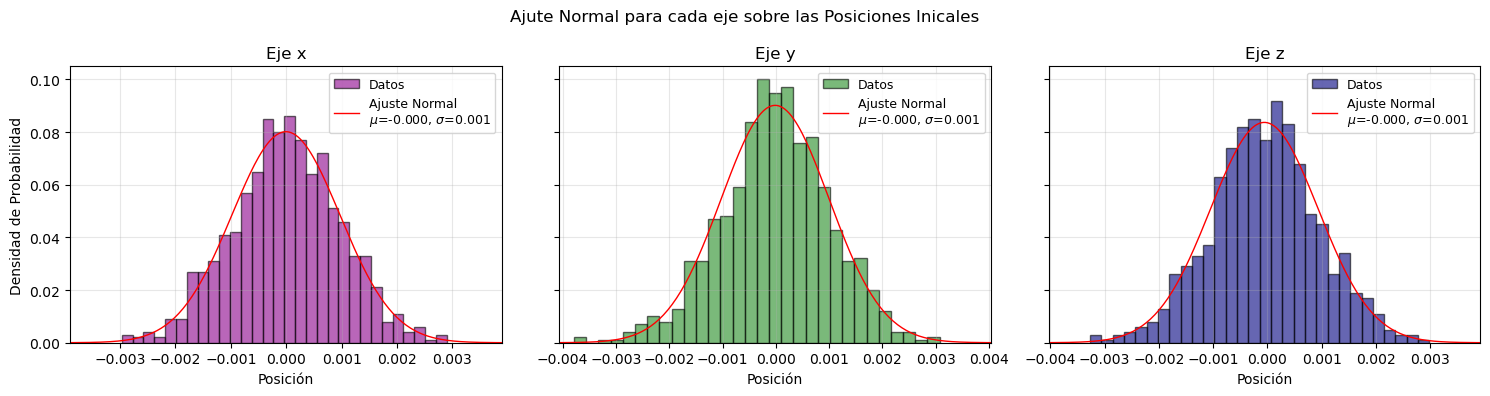

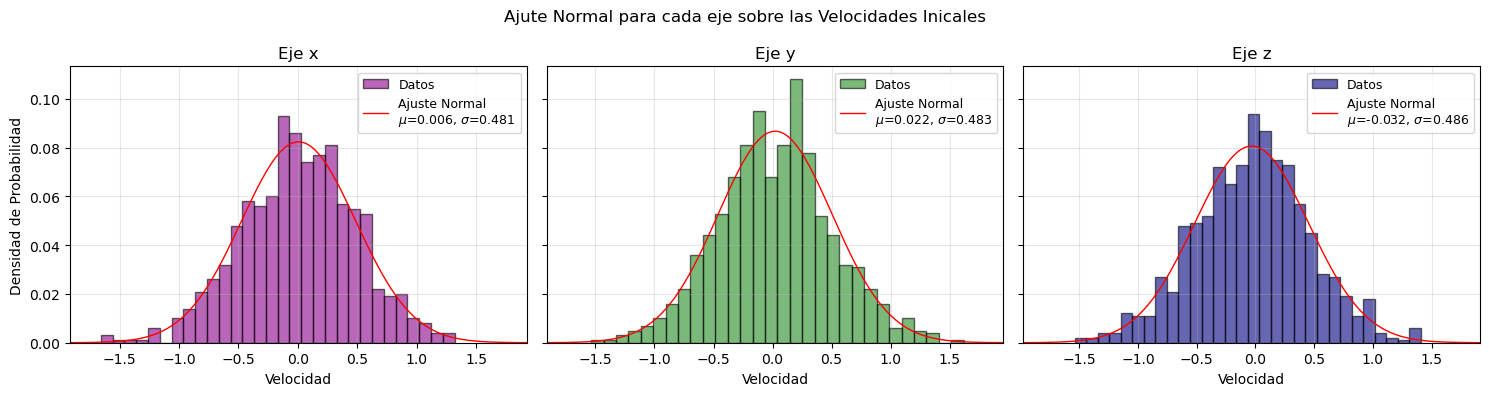

In [4]:
"""
2. Ajustes gaussianoss sobre parámetros iniciales
Graficar un histograma de las distribuciones y realizar su ajuste a una
gaussiana. Comprobar que el resultado del ajuste concuerda con los
parámetros usados para crear la distribución.
"""
bins = 30
r0_mu, r0_sigma = fit_gauss(r0, label = "Posición", title = "sobre las Posiciones Inicales")
v0_mu, v0_sigma = fit_gauss(v0, label = "Velocidad", title = "sobre las Velocidades Inicales")

"""
3. Obtener la temperatura incial del sistema
Utilice la función de distribución de velocidades de Maxwell Boltzaman para
obtener la temperatura del sistema.
"""
T0 = m*(v0_mu[0]**2 + v0_mu[1]**2+ v0_mu[2]**2)/(3*cte.k)
print(f"Temperatura inicial del sistema: {T0:.4E} K")

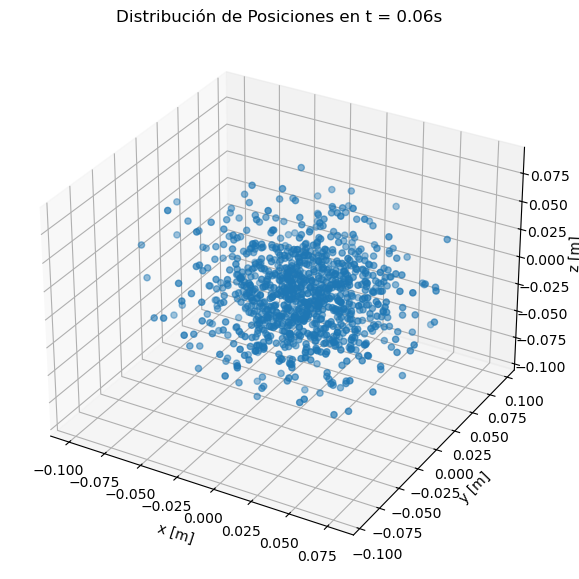

In [5]:
"""
4. Evolución temporal del movimiento de las partículas.
"""

"""
i) Las partículas no están sometidas a ninguna fuerza externa y su
velocidad es constante, esto muestra la expansión del sistema.
"""
t1 = 0.06 # tiempo en segundos (0.03 s para  una expansión x10 y 0.06 para una expansión 20)
v1 = v0 # velocidad (igual a inicial debido a que no hay fuerzas presentes, MRU) 
r1 = r0 + v1*t1 # posiciones (únicamente dependientes de la velocidad)

"""
Presentación de posiciones finales
"""
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(projection='3d')
ax.scatter(r1[:,0], r1[:,1], r1[:,2])
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_zlabel("z [m]")
plt.title(f"Distribución de Posiciones en t = {t1}s")
plt.show()

Temperatura del sistema a t = 0.06s: 5.1591E-06 K


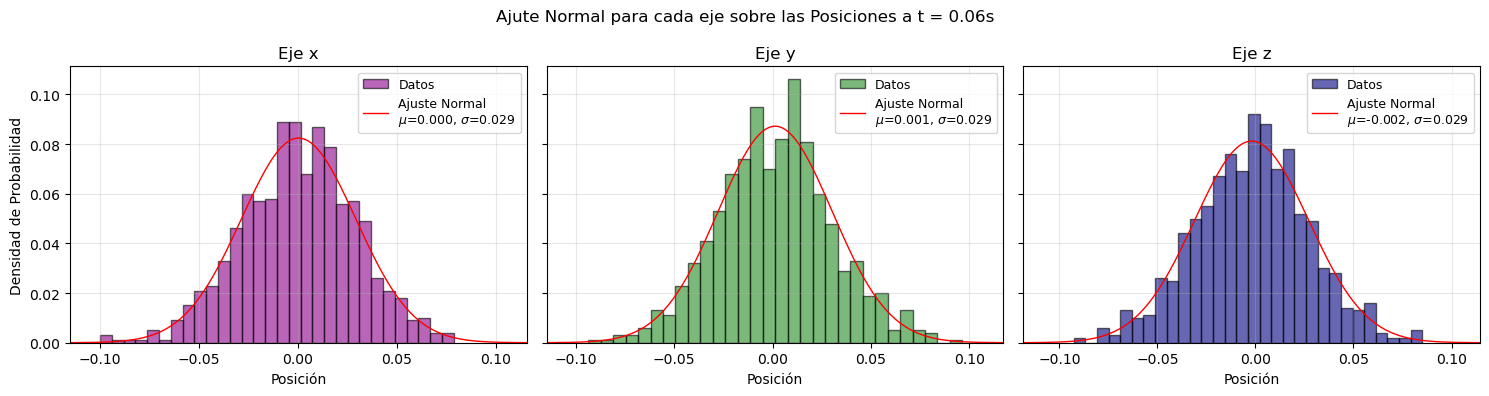

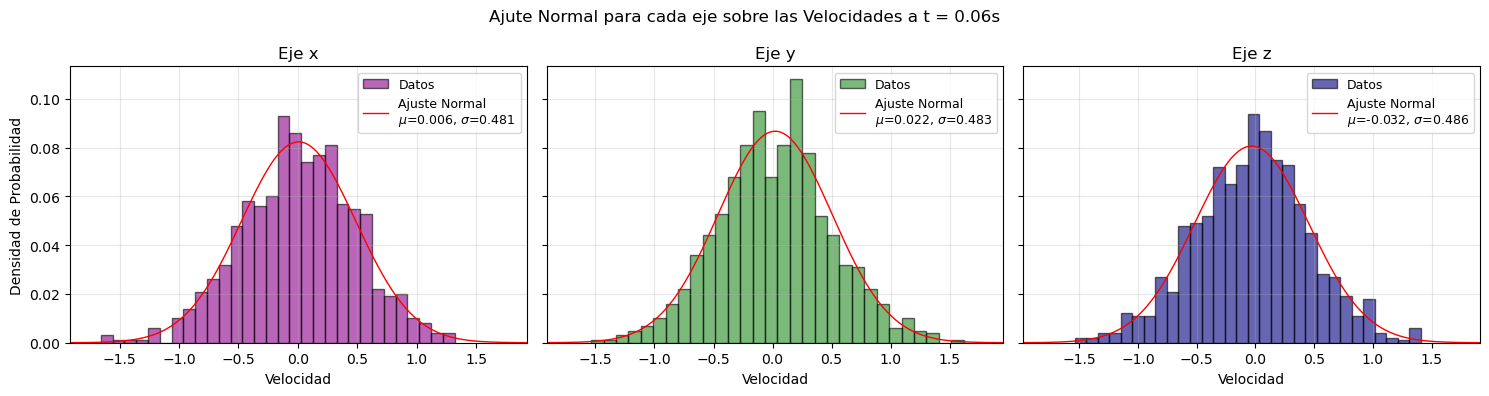

In [6]:
"""
5. Ajustes gaussianos a parámetros finales.
Graficar un histograma de las distribuciones y realizar su ajuste a una
gaussiana. Comparar los ajustes para los estados inicial y final de la evolución
temporal.
"""
bins = 30
r1_mu, r1_sigma = fit_gauss(r1, bins = bins, label = "Posición", title = f"sobre las Posiciones a t = {t1}s")
v1_mu, v1_sigma = fit_gauss(v1, bins = bins, label = "Velocidad", title = f"sobre las Velocidades a t = {t1}s")

"""
6. Obtener la temperatura final del sistema
Utilice la función de distribución de velocidades de Maxwell Boltzaman para
obtener la temperatura final del sistema.
"""
T1 = m*(v1_mu[0]**2 + v1_mu[1]**2+ v1_mu[2]**2)/(3*cte.k)
print(f"Temperatura del sistema a t = {t1}s: {T1:.4E} K")

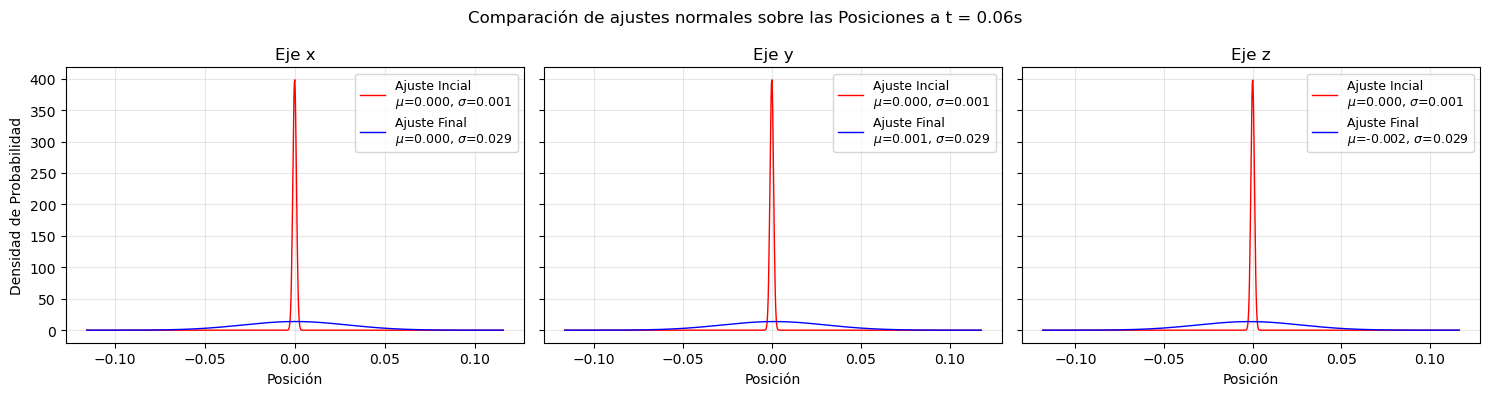

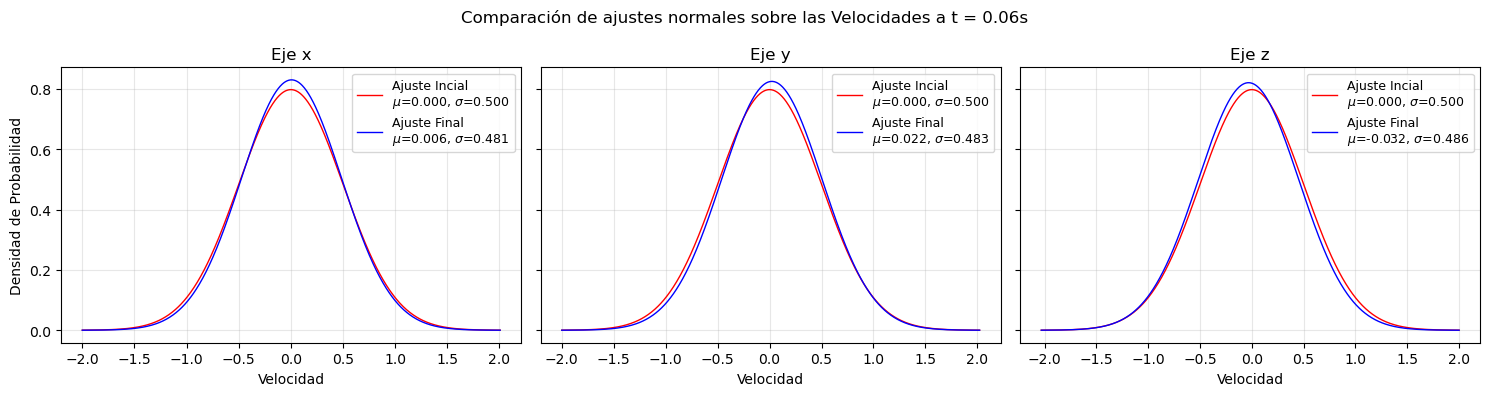

In [7]:
"""
Comparar los ajustes para los estados inicial y final de la evolución temporal.
"""
compare_fit(r_mu, r1_mu, r_sigma, r1_sigma, label = "Posición", title = f"sobre las Posiciones a t = {t1}s")
compare_fit(v_mu, v1_mu, v_sigma, v1_sigma, label = "Velocidad", title = f"sobre las Velocidades a t = {t1}s")

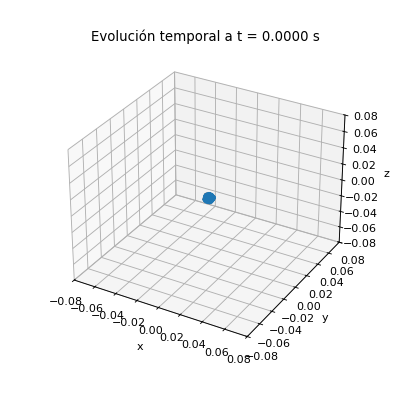

In [8]:
"""
Presentación animada de la evolución temporal
"""
animate(r0, v0, 0, t1, dt = t1/100, lim = 0.08, filename = 'simulacion1.gif')

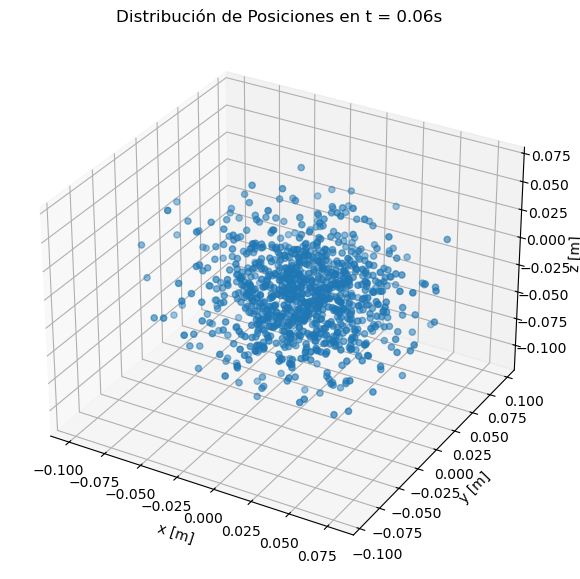

In [9]:
"""
ii) Las partículas no están sometidas a ninguna fuerza externa y su
velocidad es constante, esto muestra la expansión del sistema.
"""
t2 = 0.06 # tiempo en segundos (0.03 s para  una expansión x10 y 0.06 para una expansión 20)
v2 = v0 + [0,0, -cte.g*t2] # velocidad (modificada debido a la aceleración gravitacional, MRUA)
r2 = r0 + v0*t2 + [0,0, -0.5*cte.g*(t2**2)] # posición (obtenida de la misma forma utilizando MRUA)

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(projection='3d')
ax.scatter(r2[:,0], r2[:,1], r2[:,2])

ax.ticklabel_format(useOffset=False, axis='z')

ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_zlabel("z [m]")
plt.title(f"Distribución de Posiciones en t = {t2}s")
plt.show()

Temperatura del sistema a t = 0.06s: 1.3100E-03 K


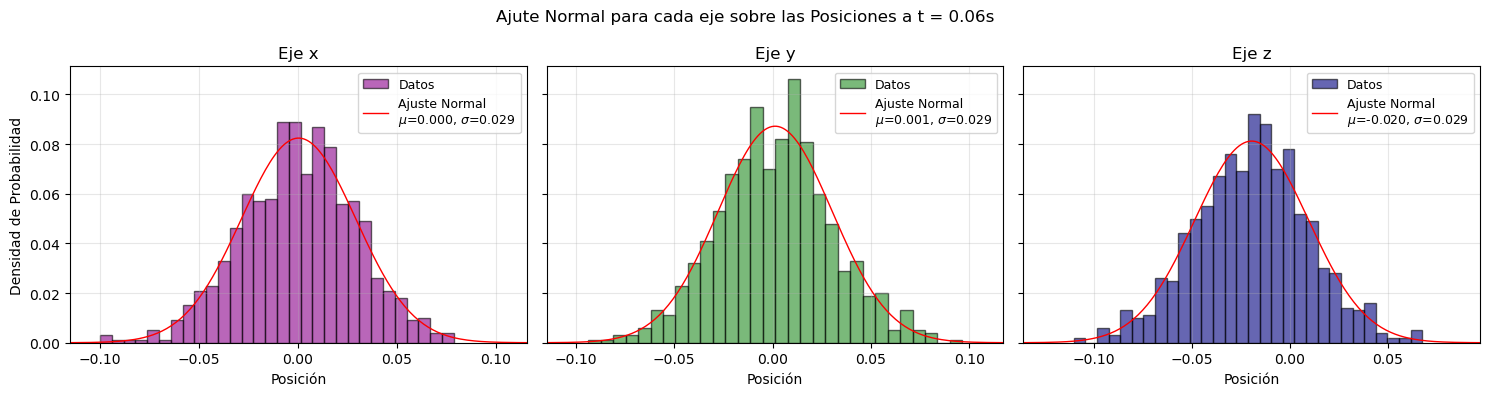

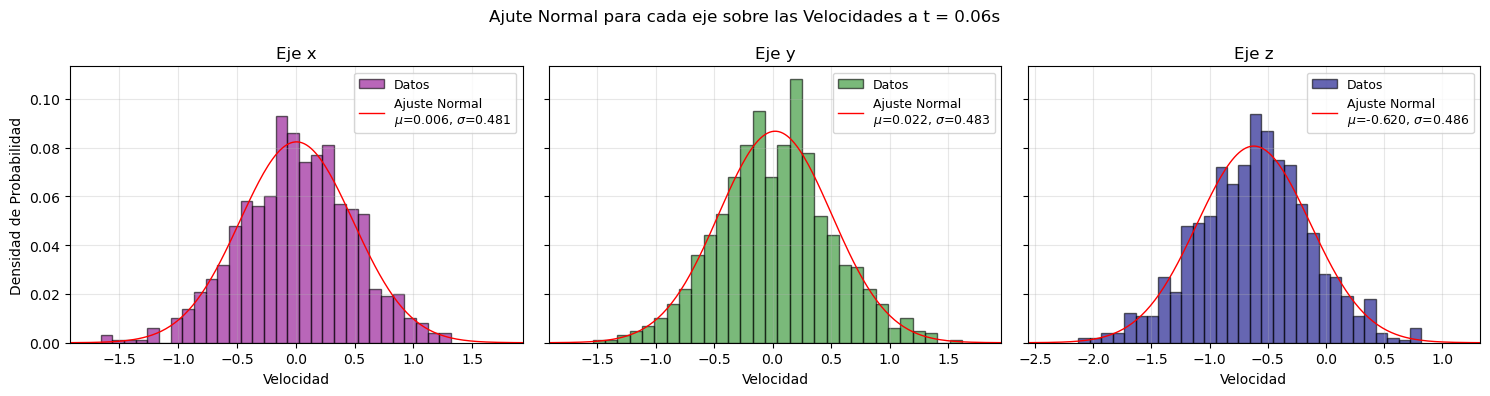

In [10]:

"""
5. Ajustes gaussianos a parámetros finales.
Graficar un histograma de las distribuciones y realizar su ajuste a una
gaussiana. 
"""
bins = 30
r2_mu, r2_sigma = fit_gauss(r2, bins = bins, label = "Posición", title = f"sobre las Posiciones a t = {t2}s")
v2_mu, v2_sigma = fit_gauss(v2, bins = bins, label = "Velocidad", title = f"sobre las Velocidades a t = {t2}s")

"""
6. Obtener la temperatura final del sistema
Utilice la función de distribución de velocidades de Maxwell Boltzaman para
obtener la temperatura final del sistema.
"""
T2 = m*(v2_mu[0]**2 + v2_mu[1]**2+ v2_mu[2]**2)/(3*cte.k)
print(f"Temperatura del sistema a t = {t2}s: {T2:.4E} K")

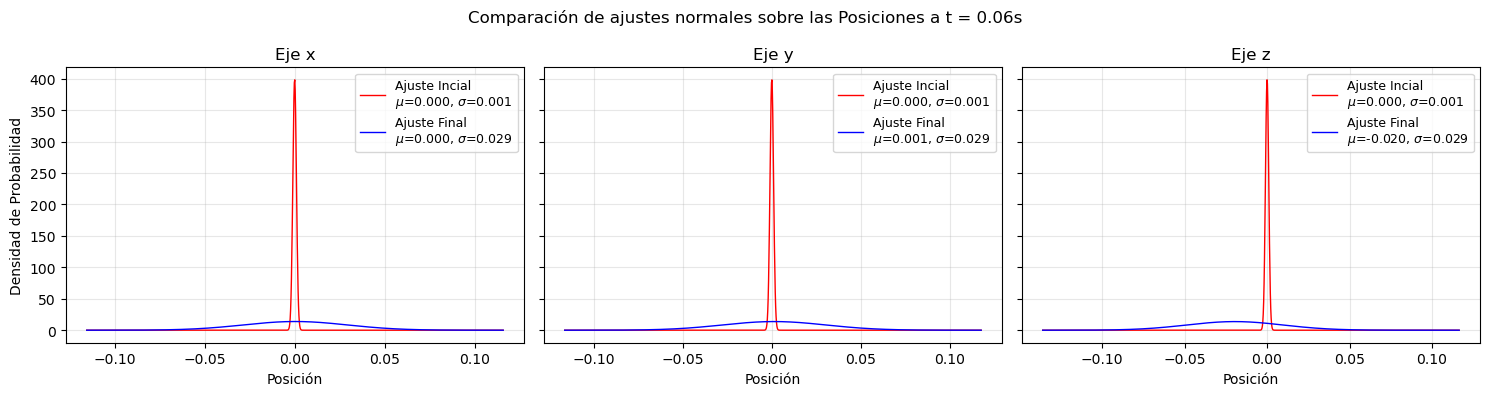

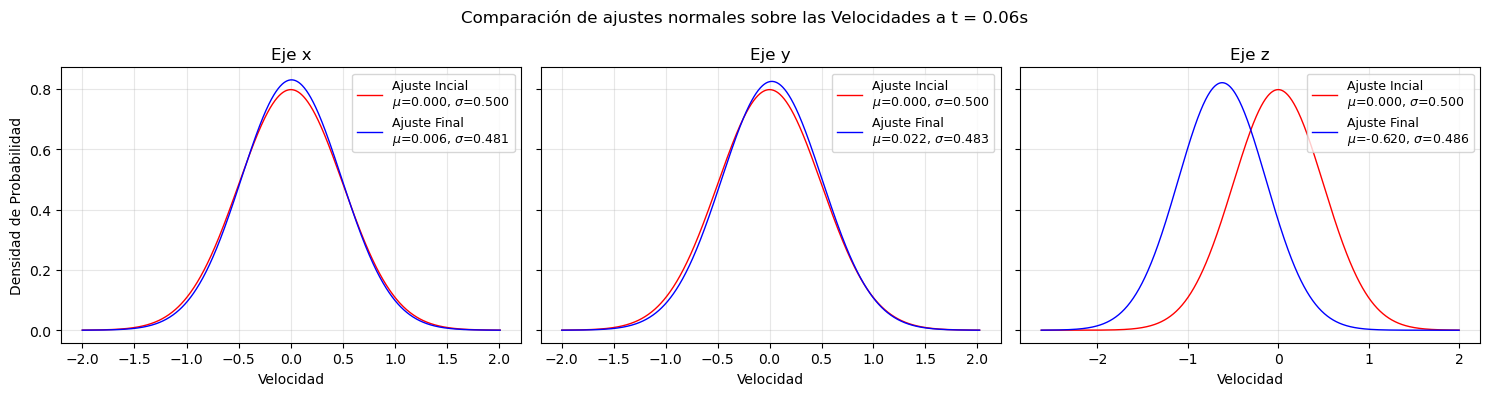

In [11]:
"""
Comparar los ajustes para los estados inicial y final de la evolución temporal.
"""
compare_fit(r_mu, r2_mu, r_sigma, r2_sigma, label = "Posición", title = f"sobre las Posiciones a t = {t2}s")
compare_fit(v_mu, v2_mu, v_sigma, v2_sigma, label = "Velocidad", title = f"sobre las Velocidades a t = {t2}s")

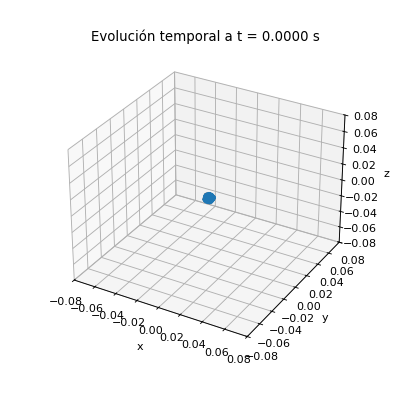

In [12]:
"""
Presentación animada de la evolución temporal
"""
animate(r0, v0, np.array([0,0,-cte.g]), t2, dt = t2/100, lim = 0.08, filename = 'simulacion2.gif')